# Introduction to Classification

In [3]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [4]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms

,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


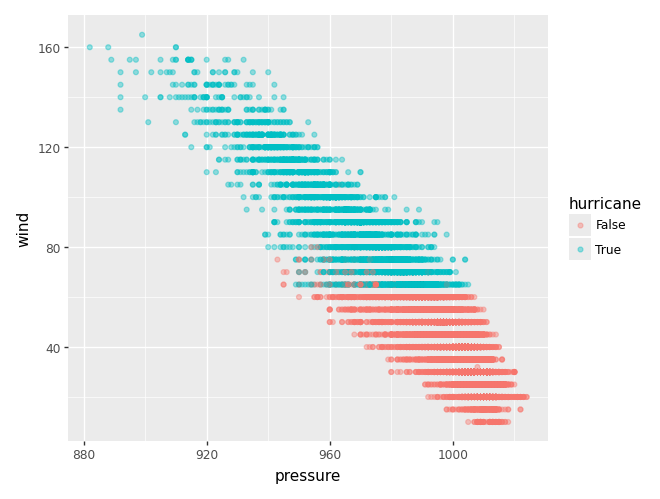

In [5]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

If wind >= 65 AND pressure <= 1000 THEN hurricane

**DISCUSS WITH YOUR PARTNER.**

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

a. 

**DISCUSS WITH YOUR PARTNER.**

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

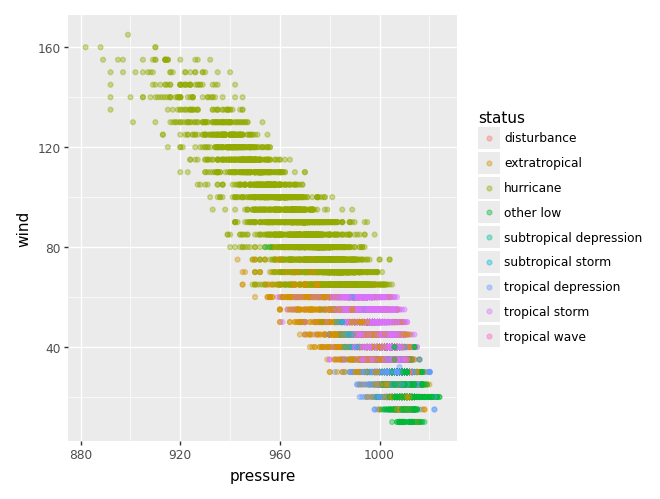

In [6]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

**DISCUSS WITH YOUR PARTNER.**

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [7]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [41]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.metrics import confusion_matrix
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

In [9]:

features = ["age", "gender", "class"]

X = df_titanic[features]
y = df_titanic["survived"]


preprocessor = make_column_transformer(
    (OneHotEncoder(drop='first', handle_unknown='ignore'), ["gender", "class"]),
    (StandardScaler(), ["age"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)
knn = make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors=10))
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('standardscaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [22]:
passenger = pd.DataFrame({
    "age": [20],
    "gender": ["female"],
    "class": ["1st"]
})

pred = knn.predict(passenger)
prob = knn.predict_proba(passenger)[:, 1]
print("Prediction:", pred, "Probability:", prob)

Prediction: [1] Probability: [1.]


In [21]:
passenger = pd.DataFrame({
    "age": [20],
    "gender": ["female"],
    "class": ["3rd"]
})

pred = knn.predict(passenger)
prob = knn.predict_proba(passenger)[:, 1]
print("Prediction:", pred, "Probability:", prob)

Prediction: [0] Probability: [0.3]


3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [ ]:
pred = knn.predict(X_test) 
cm = confusion_matrix(y_test, pred)                     # rows: actual 0, 1; columns: predicted 0, 1
TN, FP, FN, TP = cm.ravel()

precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
f1 = 2 * TP / (2 * TP + FP + FN)
print("Precision:", precision, "Recall:", recall, "F1:", f1)

Precision: 0.814 Recall: 0.5168539325842697 F1: 0.6323024054982818


Precision: Roughly 81.4% of positive predictions (survive) are actaully positive.

Recall: Roughly 51.6% of confirmed survivors were correctly predicted.

F1: Overall the model performs okay at predicting survivors, but struggles with correctly predicting those who survived, pulling the F1 score down

4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [29]:
precision = TN / (TN + FN)
recall = TN / (TN + FP)
f1 = 2 * TN / (2 * TN + FN + FP)

print("Precision:", precision, "Recall:", recall, "F1:", f1)

Precision: 0.8041002277904328 Recall: 0.9438502673796791 F1: 0.8683886838868389


Precision: Roughly 80.4% of negative predictions (didn't survive) are actually negative.

Recall: Roughly 94.4% of confirmed non-survivors were correctly predicted.

F1: Overall the model performs much better at predicting non-survivors, performing well in precision and very well in recall.

5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [45]:
prob = knn.predict_proba(X_test)[:, 1]
pred = (prob >= 0.8).astype(int)
cm = confusion_matrix(y_test, pred); TN, FP, FN, TP = cm.ravel()
print("For survivors:", "precision", TP / (TP + FP), "recall", TP / (TP + FN))
print("For non-survivors:", "precision", TN / (TN + FN), "recall", TN / (TN + FP))

For survivors: precision 0.8717948717948718 recall 0.38202247191011235
For non-survivors: precision 0.7679324894514767 recall 0.9732620320855615


**Survivors**: The precision is better as the model is more selective, reducing the number of people incorrectly labeled as a survivor, and the recall is worse as there is a decrease in the number of people who survived that were correctly predicted

**Non-survivors**: The precision is worse as the model is more selective, increasing the number of people incorrectly labeled as a non-survivor, and the recall is better as there is a decrease in the number of people who didn't survive that were correctly predicted

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

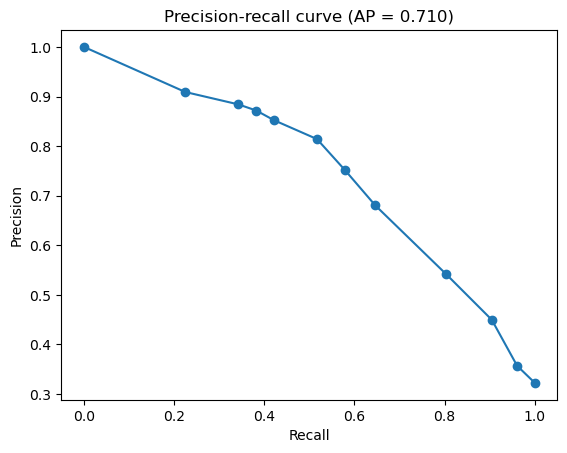

In [51]:
prob = knn.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, prob)

plt.plot(rec, prec, marker="o")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-recall curve (AP = {average_precision_score(y_test, prob):.3f})")

plt.show()

The model is fairly effective at identifying passengers who survived when making selective predictions. However, as it attempts to identify more survivors, it incorrectly classifies more non-survivors as survivors.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

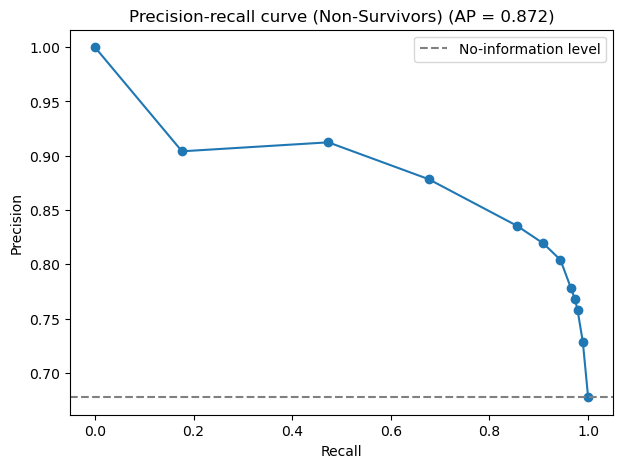

In [52]:
prob_0 = knn.predict_proba(X_test)[:, 0]

prec_0, rec_0, thr_0 = precision_recall_curve(
    y_test, prob_0, pos_label=0
)

plt.figure(figsize=(7, 5))

plt.plot(rec_0, prec_0, marker="o")
plt.axhline((y_test == 0).mean(), color="grey",
            linestyle="--", label="No-information level")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-recall curve (Non-Survivors) (AP = {average_precision_score(y_test, prob_0, pos_label=0):.3f})")
plt.legend()
plt.show()

The model is effective at identifying passengers who did not survive. Even when identifying a large proportion of actual non-survivors, most of its predictions remain correct.